# WHIRLS cruise report: platform map

Three panels on the ADT of the chosen date, with geostrophic currents, TOEddies contours and bathymetry:
(a) ship-based sampling (CTD, MVP) and autonomous vehicles, (b) profiling floats, (c) surface drifters coloured by speed.

In [1]:
from pathlib import Path
import json
import os
import re
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker
import matplotlib.transforms as mtransforms
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from cmcrameri import cm as cmc

from tools_eg import SADCP_FILES, cascade_add_time, sadcp_for_transect, sadcp_on_mvp_times

%config InlineBackend.figure_format = "retina"

In [2]:
DATE = "2026-07-13"                       # date of the ADT map and eddy contours
EXTENT = (6.0, 19.5, -42.0, -31.0)        # lon_min, lon_max, lat_min, lat_max
FIRST_LAUNCH = "2026-07-01 05:00"         # drifter fixes before this are on deck
CRUISE_END = "2026-07-27"

BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DATA = BASE / "data"
FILE_SSH = DATA / f"SSH/{DATE}_cmems_data.nc"
DIR_EDDIES = DATA / "TOEDDIES/TOEDDIES_better_ADT"
FILE_BATHY = DATA / "bathymetry/etopo2.nc"
FILE_CTD = DATA / "CTD/ctd_metadata.nc"
DIR_MVP = DATA / "MVP_Data_processed"
DIR_FLOATS = DATA / "FLOATS"
DIR_GLIDERS = DATA / "SEAGLIDERS"
DIR_WG = DATA / "WAVEGLIDERS"
FILE_XSPAR = DATA / "XSPAR/xspar_xeos_track.csv"
FILE_DRIFTERS = DATA / "DRIFTERS/drifters_tracks.geojson"
OUT_DIR = BASE / "figures"
DRIFT_CACHE = OUT_DIR / "drifters_clean_geojson.csv"   # delete to re-clean the drifters

In [3]:
# ---------------------------------------------------------------------------
# Reading the platform tracks
# ---------------------------------------------------------------------------
def read_table(path):
    """CSV with ; , or tab separators, chosen separately for the header and the data
    (seaexplorer.csv has a ';' header and ',' rows)."""
    with open(path, encoding="utf-8-sig") as f:
        lines = [next(f, "") for _ in range(6)]
    header, data = lines[0], "".join(l for l in lines[1:] if l.strip())
    pick = lambda txt: max([";", ",", "\t"], key=txt.count)
    sep_h, sep_d = pick(header), pick(data)
    if sep_h == sep_d:
        return pd.read_csv(path, sep=sep_d, encoding="utf-8-sig")
    names = [c.strip() for c in header.strip().split(sep_h)]
    return pd.read_csv(path, sep=sep_d, header=None, skiprows=1, names=names,
                       encoding="utf-8-sig")


def parse_time(col):
    """Datetime from strings (day-first or month-first) or Unix epoch (s or ms)."""
    num = pd.to_numeric(col, errors="coerce")
    if num.notna().mean() > 0.9:
        return pd.to_datetime(num, unit="ms" if num.median() > 1e11 else "s", errors="coerce")
    t1 = pd.to_datetime(col, dayfirst=True, errors="coerce")
    t2 = pd.to_datetime(col, dayfirst=False, errors="coerce")
    t = t1 if t1.notna().sum() >= t2.notna().sum() else t2
    return t.dt.tz_convert(None) if t.dt.tz is not None else t


def read_track(path):
    """Track file -> DataFrame (time, lon, lat) sorted in time, without missing fixes."""
    df = read_table(path)
    df.columns = df.columns.str.strip().str.lower()
    tcol = next(c for c in df.columns if "time" in c or "date" in c)
    lon = next(c for c in df.columns if c.startswith("lon"))
    lat = next(c for c in df.columns if c.startswith("lat"))
    df = pd.DataFrame({"time": parse_time(df[tcol]),
                       "lon": pd.to_numeric(df[lon], errors="coerce"),
                       "lat": pd.to_numeric(df[lat], errors="coerce")})
    return df.dropna().sort_values("time").drop_duplicates("time").reset_index(drop=True)


def float_label(fname):
    """'argo_1902784.csv' -> '1902784', 'uvp_float_6596_locations.csv' -> 'UVP 6596',
    'mr_float_soton_positions.csv' -> 'MR SOTON'."""
    stem = Path(fname).stem
    if stem.startswith("argo"):
        return stem.split("_")[1]
    words = [w.upper() for w in stem.split("_")[1:] if w not in ("float", "locations", "positions")]
    return " ".join([stem.split("_")[0].upper()] + words)


def glider_label(fname):
    """'sg283_track.csv' -> 'SG283', 'seaexplorer.csv' -> 'SGSE'."""
    stem = Path(fname).stem.lower()
    return "SGSE" if "seaexplorer" in stem else re.search(r"sg(\d+)", stem).group(0).upper()


def dist_m(lon1, lat1, lon2, lat2):
    """Great-circle distance (m)."""
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371e3 * np.arcsin(np.sqrt(a))


def in_water_pieces(t, lon, lat, max_speed=1.5, window_h=1.0, min_piece_h=12):
    """Index ranges (i0, i1) where a wave glider moves slower than max_speed (m/s,
    measured over ~window_h) for at least min_piece_h. Faster = on the ship."""
    n = len(lon)
    ts = t.astype("datetime64[s]").astype(float)
    j = np.minimum(np.searchsorted(ts, ts + window_h * 3600), n - 1)
    dt = ts[j] - ts
    dx = np.deg2rad(lon[j] - lon) * np.cos(np.deg2rad(0.5 * (lat[j] + lat)))
    d = 6371e3 * np.hypot(dx, np.deg2rad(lat[j] - lat))
    with np.errstate(divide="ignore", invalid="ignore"):
        spd = pd.Series(np.where(dt > 0, d / dt, np.nan)).ffill().bfill().values
    slow = spd <= max_speed
    pieces, start = [], None
    for k in range(n + 1):
        if k < n and slow[k]:
            start = k if start is None else start
        elif start is not None:
            if (ts[k - 1] - ts[start]) / 3600 >= min_piece_h:
                pieces.append((start, k))
            start = None
    return pieces


def break_long_jumps(lon, lat, max_km):
    """Insert NaN between consecutive fixes more than max_km apart."""
    dx = np.deg2rad(np.diff(lon)) * np.cos(np.deg2rad(0.5 * (lat[1:] + lat[:-1])))
    d = 6371.0 * np.hypot(dx, np.deg2rad(np.diff(lat)))
    cut = np.flatnonzero(d > max_km) + 1
    return np.insert(lon, cut, np.nan), np.insert(lat, cut, np.nan)


# ---------------------------------------------------------------------------
# Drifters
# ---------------------------------------------------------------------------
def add_speed(df):
    """Speed (m/s) and gap (h) from each fix to the next fix of the same drifter."""
    g = df.groupby("id")
    df["dt_h"] = (g["time"].shift(-1) - df["time"]).dt.total_seconds() / 3600
    df["speed"] = dist_m(df["lon"], df["lat"], g["lon"].shift(-1), g["lat"].shift(-1)) / (df["dt_h"] * 3600)
    return df


def read_drifter_geojson(path):
    """Fixes (id, time, lon, lat) rebuilt from the 'track_segment' features, the only
    ones with times. Speeds are recomputed from positions (speed_mps is unreliable)."""
    with open(path) as f:
        feats = json.load(f)["features"]
    rows = []
    for ft in feats:
        p = ft["properties"]
        if p.get("kind") == "track_segment":
            (lon0, lat0), (lon1, lat1) = [c[:2] for c in ft["geometry"]["coordinates"]]
            rows.append((p["D_number"], p["start_date"], lon0, lat0))
            rows.append((p["D_number"], p["end_date"], lon1, lat1))
    df = pd.DataFrame(rows, columns=["id", "time", "lon", "lat"])
    df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_localize(None)
    return df.drop_duplicates(["id", "time"]).sort_values(["id", "time"]).reset_index(drop=True)


def clean_drifters(df, max_deploy_speed=1.5, max_gap_days=2, spike_speed=3.0,
                   match_hours=6, match_km=25):
    """Drop the on-deck fixes before each deployment, then GPS spikes."""
    df = add_speed(df.copy())
    clear = (df["speed"] < max_deploy_speed) & (df["dt_h"] < max_gap_days * 24)

    # deployment events: first clear fixes, grouped within match_hours and match_km
    first = df.groupby("id").head(1)
    first = first[clear.loc[first.index]].sort_values("time")
    near = lambda r, e: (abs((r.time - e[0]).total_seconds()) < match_hours * 3600
                         and dist_m(r.lon, r.lat, e[1], e[2]) < match_km * 1e3)
    events = []
    for _, r in first.iterrows():
        if not any(near(r, e) for e in events):
            events.append((r.time, r.lon, r.lat))

    # each drifter starts at its first fix near an event (or its first clear fix)
    keep = []
    for _, g in df.groupby("id", sort=False):
        start = next((i for i, (idx, r) in enumerate(g.iterrows())
                      if clear[idx] or any(near(r, e) for e in events)), None)
        if start is not None:
            keep.append(g.iloc[start:])
    df = pd.concat(keep).reset_index(drop=True)

    for _ in range(3):
        df = add_speed(df)
        spike = (df["speed"] > spike_speed) & (df.groupby("id")["speed"].shift(1) > spike_speed)
        if not spike.any():
            break
        df = df[~spike].reset_index(drop=True)
    return add_speed(df)


# ---------------------------------------------------------------------------
# Map drawing
# ---------------------------------------------------------------------------
def draw_background(ax):
    """Same background on every panel: ADT, currents, ADT isolines, land, bathymetry, eddies."""
    pc = ccrs.PlateCarree()
    ax.set_extent(EXTENT, crs=pc)
    img = ax.imshow(adt, extent=[LON.min(), LON.max(), LAT.min(), LAT.max()], origin="lower",
                    cmap=cmc.vik, vmin=-0.7, vmax=1.7, alpha=0.8, interpolation="bilinear",
                    transform=pc, zorder=1)

    MLON, MLAT = np.meshgrid(LON, LAT)
    q = ax.quiver(MLON[::2, ::2], MLAT[::2, ::2], ugos[::2, ::2], vgos[::2, ::2],
                  color="k", alpha=0.9, scale=110, scale_units="width", width=0.0007,
                  headwidth=3.0, headlength=3.5, headaxislength=3.15, transform=pc, zorder=4)
    ax.quiverkey(q, 0.86, 1.04, 1.0, "1 m s$^{-1}$", labelpos="E", coordinates="axes",
                 fontproperties={"size": 8})

    levels = np.arange(np.floor(np.nanmin(adt) / 0.1) * 0.1, np.ceil(np.nanmax(adt) / 0.1) * 0.1 + 0.05, 0.1)
    cs = ax.contour(LON, LAT, adt, levels=levels, colors="0.15", linewidths=0.5,
                    linestyles="solid", alpha=0.6, transform=pc, zorder=3)
    ax.clabel(cs, fmt="%.1f", fontsize=5, inline=True, inline_spacing=2)

    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", zorder=2)
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6, zorder=3)

    bathy_lw = [0.35 * (1 + 0.25 * i / (len(BATHY_LEVELS) - 1)) for i in range(len(BATHY_LEVELS))]
    ax.contour(bathy["lon"], bathy["lat"], -bathy, levels=BATHY_LEVELS, colors="0.45",
               linewidths=bathy_lw, linestyles="solid", alpha=0.7, transform=pc, zorder=2.5)

    halo = [pe.withStroke(linewidth=2.4, foreground="white", alpha=0.5)]
    for kind, ls in (("anticyclones", "--"), ("cyclones", "-")):
        for x, y in eddies[kind]:
            ax.plot(x, y, ls, color="0.3", lw=1.0, path_effects=halo, transform=pc, zorder=5)
    for x, y in eddies["centers"]:
        ax.plot(x, y, "+", color="0.3", ms=4, mew=1.4, path_effects=halo, transform=pc, zorder=6)
    return img


def finish_axes(ax):
    """Ticks every 2 degrees, labels, grid."""
    lon0, lon1, lat0, lat1 = EXTENT
    ax.set_xticks(np.arange(2 * np.floor(lon0 / 2), 2 * np.ceil(lon1 / 2) + 0.1, 2), crs=ccrs.PlateCarree())
    ax.set_yticks(np.arange(2 * np.floor(lat0 / 2), 2 * np.ceil(lat1 / 2) + 0.1, 2), crs=ccrs.PlateCarree())
    ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
    ax.yaxis.set_major_formatter(LatitudeFormatter())
    ax.xaxis.set_minor_locator(mticker.AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(mticker.AutoMinorLocator(4))
    ax.tick_params(which="major", length=6, width=0.8, direction="out", top=True, right=True, labelsize=9)
    ax.tick_params(which="minor", length=3, width=0.5, direction="out", top=True, right=True)
    ax.tick_params(labeltop=False, labelright=False)
    ax.grid(which="major", color="white", alpha=0.45, linewidth=0.4, linestyle=":", zorder=6)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())     # the ticks must not widen the map


def background_handles():
    return [
        mlines.Line2D([], [], color="0.15", lw=1.0, alpha=0.6, label="ADT isolines (0.1 m)"),
        mlines.Line2D([], [], color="0.3", ls="-", lw=1.0, label="Cyclone"),
        mlines.Line2D([], [], color="0.3", ls="--", lw=1.0, label="Anticyclone"),
        mlines.Line2D([], [], color="0.45", lw=0.7, label="Bathymetry"),
    ]


def draw_deploy(ax, lon, lat, marker, ms, col, nudge=(0, 0)):
    """Deployment marker, optionally shifted by `nudge` (points) with a leader line
    to a small black dot at the real position."""
    base = ccrs.PlateCarree()._as_mpl_transform(ax)
    tr = base
    if nudge != (0, 0):
        tr = mtransforms.offset_copy(base, fig=ax.figure, x=nudge[0], y=nudge[1], units="points")
        ax.annotate("", xy=(lon, lat), xycoords=base, xytext=nudge, textcoords="offset points",
                    zorder=999, arrowprops=dict(arrowstyle="-", color="k", lw=0.6, shrinkA=0, shrinkB=0))
        ax.plot(lon, lat, "o", ms=2, color="k", transform=base, zorder=1000)
    ax.plot(lon, lat, marker, ms=ms, mfc=col, mec="k", mew=0.4, transform=tr, zorder=1001)


def first_fix(lon, lat):
    i = np.flatnonzero(np.isfinite(lon) & np.isfinite(lat))[0]
    return lon[i], lat[i]


def side_by_side_offsets(tracks, group_deg=0.1, split_pt=3.0, marker_gap_pt=8.0, away_km=30):
    """Tracks starting at (almost) the same spot are drawn side by side.
    Returns {i: (track_dx, track_dy, marker_dx, marker_dy)} in points, perpendicular
    to the direction the group heads off in."""
    starts = [first_fix(lon, lat) for _, lon, lat in tracks]
    groups = []
    for i, (x, y) in enumerate(starts):
        for g in groups:
            if np.hypot(x - starts[g[0]][0], y - starts[g[0]][1]) < group_deg:
                g.append(i)
                break
        else:
            groups.append([i])
    out = {}
    for g in [g for g in groups if len(g) > 1]:
        x0, y0 = starts[g[0]]
        heads = []
        for i in g:
            _, lon, lat = tracks[i]
            d = np.hypot((lon - x0) * np.cos(np.radians(y0)), lat - y0) * 111
            far = np.flatnonzero(np.isfinite(d) & (d > away_km))
            j = far[0] if far.size else np.flatnonzero(np.isfinite(d))[-1]
            heads.append((lon[j] - x0, lat[j] - y0))
        hx, hy = np.mean(heads, axis=0)
        nrm = np.hypot(hx, hy) or 1.0
        px, py = -hy / nrm, hx / nrm
        for m, i in enumerate(g):
            k = m - (len(g) - 1) / 2
            out[i] = (k * split_pt * px, k * split_pt * py, k * marker_gap_pt * px, k * marker_gap_pt * py)
    return out


def speed_cmap(smin, smax, yellow_until=0.3):
    """Ochre for slow drifters (below yellow_until m/s), then green to dark green."""
    f = np.clip((yellow_until - smin) / (smax - smin), 0.15, 0.85)
    return LinearSegmentedColormap.from_list("drifter_speed", [
        (0.0, "#c99700"), (f, "#a67c00"), (f + 0.35 * (1 - f), "#4a9e2f"), (1.0, "#00441b")])


def side_cbar(ax, mappable, label, side):
    """Vertical colour bar on the outer edge of a panel ('left' or 'right')."""
    p = ax.get_position()
    x = p.x0 - 0.055 if side == "left" else p.x1 + 0.008
    cax = fig.add_axes([x, p.y0 + 0.12 * p.height, 0.007, 0.76 * p.height])
    cb = fig.colorbar(mappable, cax=cax)
    cb.set_label(label)
    cb.solids.set_alpha(1)
    if side == "left":
        cax.yaxis.set_ticks_position("left")
        cax.yaxis.set_label_position("left")

In [4]:
# ---------------------------------------------------------------------------
# SSH, bathymetry, eddies, CTD
# ---------------------------------------------------------------------------
ssh = xr.open_dataset(FILE_SSH).squeeze().sel(longitude=slice(EXTENT[0], EXTENT[1]),
                                              latitude=slice(EXTENT[2], EXTENT[3]))
LON, LAT = ssh["longitude"].values, ssh["latitude"].values
adt, ugos, vgos = ssh["adt"].values, ssh["ugos"].values, ssh["vgos"].values

BATHY_LEVELS = [100, 200, 500, 1000, 2000, 3000, 4000, 5000]
bathy = xr.open_dataset(FILE_BATHY)["topo"].sel(lon=slice(EXTENT[0] - 1, EXTENT[1] + 1),
                                                lat=slice(EXTENT[2] - 1, EXTENT[3] + 1))

def eddy_shapes(kind, part):
    geoms = gpd.read_file(DIR_EDDIES / f"{DATE.replace('-', '')}_{kind}_{part}.geojson").geometry.dropna()
    if part == "centers":
        return [(g.x, g.y) for g in geoms]
    return [g.exterior.xy for g in geoms]

eddies = {kind: eddy_shapes(kind, "outcontour") + eddy_shapes(kind, "maxspeed")
          for kind in ("anticyclones", "cyclones")}
eddies["centers"] = eddy_shapes("anticyclones", "centers") + eddy_shapes("cyclones", "centers")

ctd = xr.open_dataset(FILE_CTD)
ctd_lon, ctd_lat = ctd["lon_start"].values, ctd["lat_start"].values

In [5]:
# ---------------------------------------------------------------------------
# MVP transects -> one position per cast
# (missing MVP positions are filled with the ship position from the SADCP)
# ---------------------------------------------------------------------------
sadcp = cascade_add_time(xr.open_dataset(SADCP_FILES["OS150"])).sortby("time")
sadcp = sadcp.isel(time=~sadcp.indexes["time"].duplicated())

mvp_tracks = []
transects = sorted((d for d in os.listdir(DIR_MVP) if d.startswith("transect ")),
                   key=lambda d: int(d.split()[-1]))
for name in transects:
    files = sorted((DIR_MVP / name).glob("*.csv"))
    mvp = pd.concat([pd.read_csv(f).assign(CAST=k) for k, f in enumerate(files)], ignore_index=True)

    if mvp[["LON (°E)", "LAT (°N)"]].isna().any().any():
        ship = sadcp_on_mvp_times(mvp, sadcp_for_transect(mvp, sadcp), max_gap="30min",
                                  keep=("LATITUDE", "LONGITUDE"))
        mvp["LON (°E)"] = mvp["LON (°E)"].fillna(pd.Series(ship["LONGITUDE"].values, index=mvp.index))
        mvp["LAT (°N)"] = mvp["LAT (°N)"].fillna(pd.Series(ship["LATITUDE"].values, index=mvp.index))

    casts = (mvp.assign(t=pd.to_datetime(mvp["TIME"]))
                .groupby("CAST")
                .agg(lon=("LON (°E)", "mean"), lat=("LAT (°N)", "mean"), t=("t", "min"))
                .dropna(subset=["lon", "lat"])
                .sort_values("t"))
    mvp_tracks.append((casts["lon"].values, casts["lat"].values))

# ---------------------------------------------------------------------------
# Floats, gliders, wave gliders, XSPAR -> (label, lon, lat)
# ---------------------------------------------------------------------------
float_tracks, float_t0 = [], {}
for f in sorted(os.listdir(DIR_FLOATS)):
    if f.endswith(".csv") and f.startswith(("argo", "uvp", "mr")):
        tr = read_track(DIR_FLOATS / f)
        float_tracks.append((float_label(f), tr["lon"].values, tr["lat"].values))
        float_t0[float_label(f)] = tr["time"].iloc[0]

glider_tracks = []
for f in sorted(os.listdir(DIR_GLIDERS)):
    if f.endswith(".csv"):
        tr = read_track(DIR_GLIDERS / f)
        glider_tracks.append((glider_label(f), tr["lon"].values, tr["lat"].values))
glider_tracks.sort(key=lambda g: (g[0] == "SGSE", g[0]))      # SG numbers first, SGSE last

# Wave gliders: only the in-water pieces (no lines along the ship legs)
wg_tracks = []
for label, fname in (("WG Melktert", "melktert_track.csv"), ("WG Vetkoek", "vetkoek_track.csv")):
    tr = read_track(DIR_WG / fname)
    lon, lat = tr["lon"].values, tr["lat"].values
    pieces = in_water_pieces(tr["time"].values, lon, lat)
    if label == "WG Vetkoek":
        pieces = pieces[-1:]          # only its last deployment (the filament, 17-22 Jul)
    lon = np.concatenate([np.r_[lon[a:b], np.nan] for a, b in pieces])[:-1]
    lat = np.concatenate([np.r_[lat[a:b], np.nan] for a, b in pieces])[:-1]
    wg_tracks.append((label, lon, lat))

tr = read_track(FILE_XSPAR)
xspar_lon, xspar_lat = break_long_jumps(tr["lon"].values, tr["lat"].values, max_km=30)

# ---------------------------------------------------------------------------
# Drifters -> segments between consecutive fixes, coloured by speed
# ---------------------------------------------------------------------------
if DRIFT_CACHE.exists():
    drift = pd.read_csv(DRIFT_CACHE, parse_dates=["time"])
else:
    raw = read_drifter_geojson(FILE_DRIFTERS)
    drift = clean_drifters(raw[raw["time"] >= pd.Timestamp(FIRST_LAUNCH)])
    drift[["id", "time", "lon", "lat"]].to_csv(DRIFT_CACHE, index=False)

drift = drift.sort_values(["id", "time"])
drift = add_speed(drift[drift["time"] <= pd.Timestamp(CRUISE_END) + pd.Timedelta("1D")].reset_index(drop=True))

segs, seg_speed, drift_deploy = [], [], []
for _, g in drift.groupby("id"):
    lon, lat, spd, dt_h = (g[c].values[:-1] for c in ("lon", "lat", "speed", "dt_h"))
    drift_deploy.append((g["lon"].iloc[0], g["lat"].iloc[0]))
    ok = (dt_h > 0) & (dt_h <= 13) & (spd < 3)       # no segment across gaps or on-deck legs
    s = np.stack([np.c_[g["lon"].values[:-1], g["lat"].values[:-1]],
                  np.c_[g["lon"].values[1:], g["lat"].values[1:]]], axis=1)
    segs.append(s[ok])
    seg_speed.append(spd[ok])
segs, seg_speed, drift_deploy = np.concatenate(segs), np.concatenate(seg_speed), np.array(drift_deploy)

print(f"{len(ctd_lon)} CTD casts, {len(mvp_tracks)} MVP transects, {len(float_tracks)} floats, "
      f"{len(glider_tracks)} gliders, {len(wg_tracks)} wave gliders, {len(drift_deploy)} drifters")

105 CTD casts, 16 MVP transects, 17 floats, 4 gliders, 2 wave gliders, 200 drifters


/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_44089/2109406993.py:24: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  t1 = pd.to_datetime(col, dayfirst=True, errors="coerce")
/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_44089/2109406993.py:24: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  t1 = pd.to_datetime(col, dayfirst=True, errors="coerce")
/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_44089/2109406993.py:24: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  t1 = pd.to_datetime(col, dayfirst=True, errors="coerce")
/var/folders/lg/5krm8xnn5xv0smms_psmknp40000gn/T/ipykernel_44089/2109406993.py:24: UserWarning: Parsing da

Saved /Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/2026-07-13_WHIRLS_platforms_floats_drifters.png


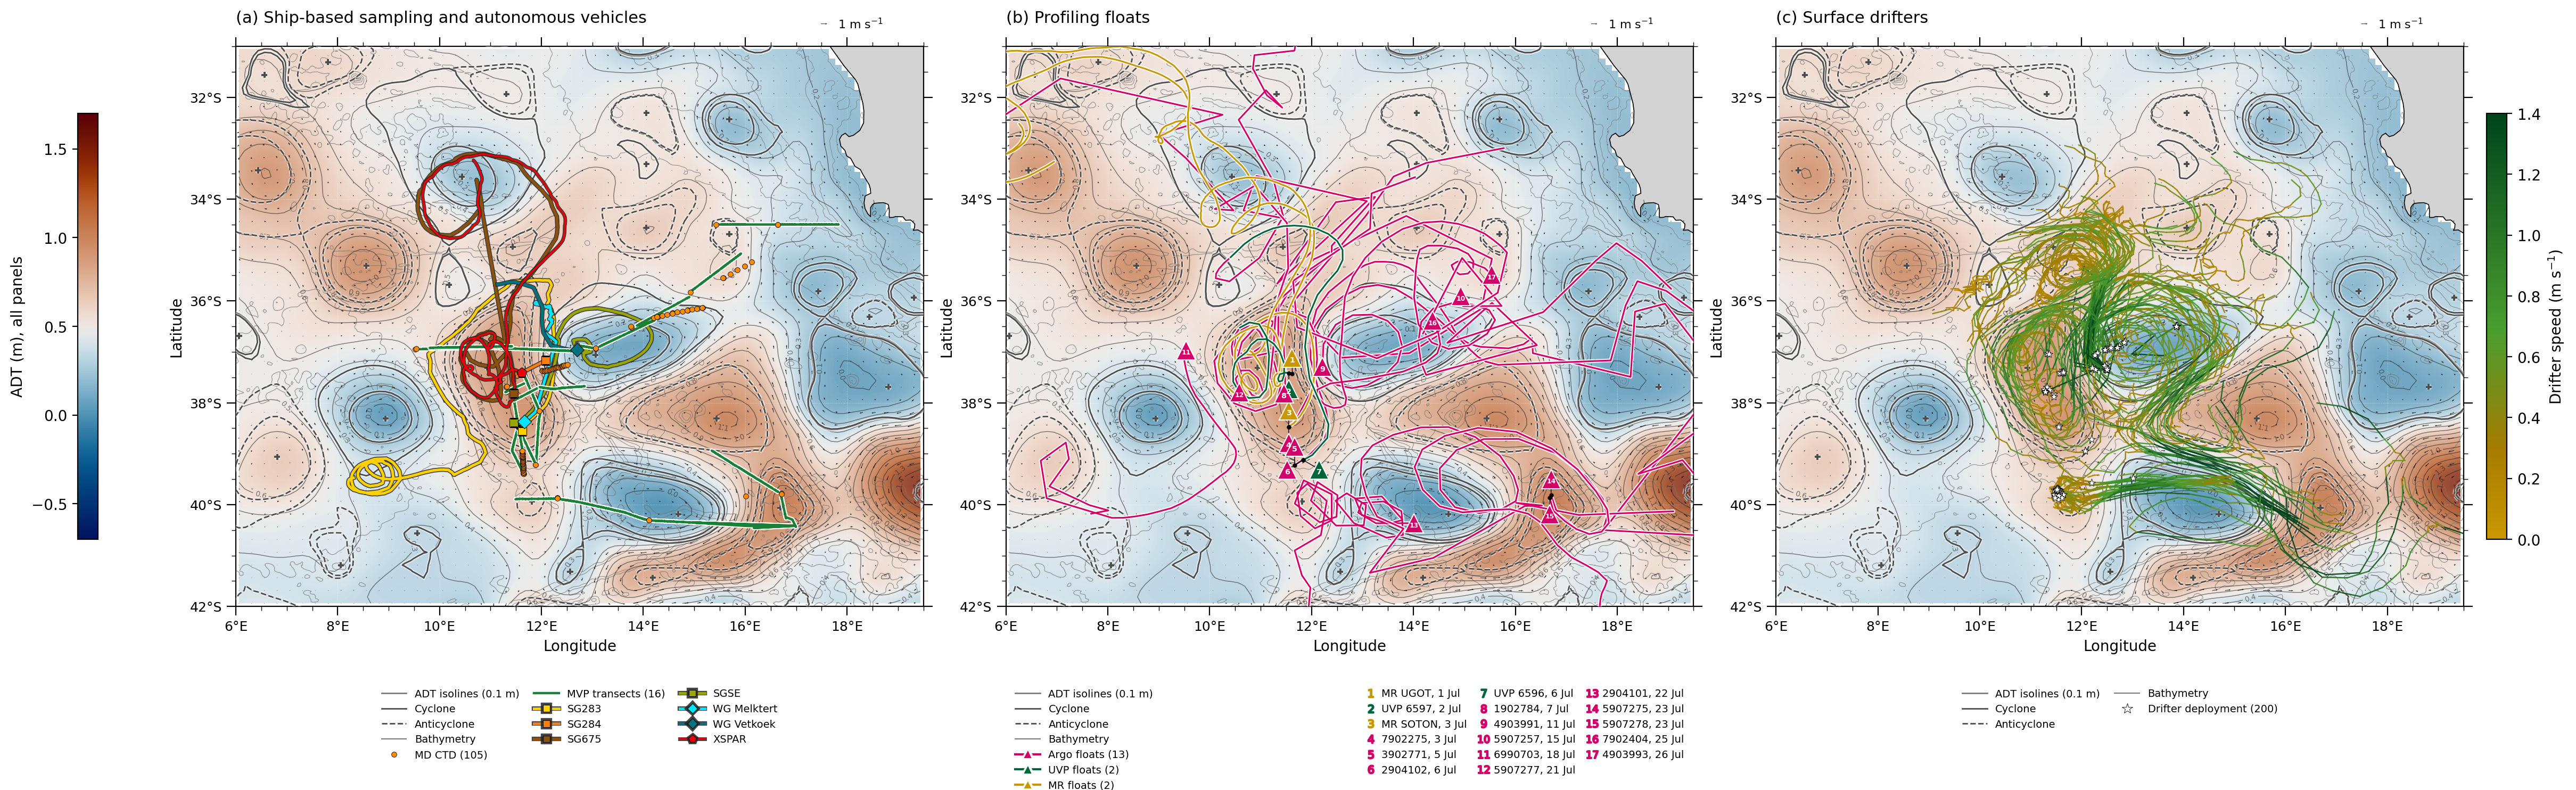

In [6]:
pc = ccrs.PlateCarree()
LEG_KW = dict(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=7, frameon=False,
              columnspacing=1.4, handlelength=2.4)
TITLE_KW = dict(loc="left", fontsize=11, pad=16)

fig = plt.figure(figsize=(27, 8.6))
ax = fig.add_subplot(1, 3, 1, projection=pc)
axf = fig.add_subplot(1, 3, 2, projection=pc)
axd = fig.add_subplot(1, 3, 3, projection=pc)
fig.subplots_adjust(wspace=0.12)

# ======================= (a) CTD, MVP, gliders, wave gliders, XSPAR =======================
img = draw_background(ax)

GLIDER_COLORS = ["#ffd000", "#ff7f0e", "#8c510a", "#9aa600"]
WG_COLORS = ["#00e5ff", "#00727f"]
XSPAR_COLOR, MVP_COLOR, CTD_COLOR = "#e8000b", "#1a7f37", "#FF8C00"
dark_halo = lambda lw: [pe.Stroke(linewidth=lw, foreground="0.15", alpha=0.85), pe.Normal()]
mvp_halo = [pe.Stroke(linewidth=3.2, foreground="white", alpha=0.9), pe.Normal()]

# co-deployed gliders are drawn side by side
offsets = side_by_side_offsets(glider_tracks)
for i, ((label, lon, lat), col) in enumerate(zip(glider_tracks, GLIDER_COLORS)):
    tdx, tdy, mdx, mdy = offsets.get(i, (0, 0, 0, 0))
    tr = mtransforms.offset_copy(pc._as_mpl_transform(ax), fig=fig, x=tdx, y=tdy, units="points")
    ax.plot(lon, lat, color=col, lw=1.8, path_effects=dark_halo(3.0), transform=tr, zorder=6.8)
    draw_deploy(ax, *first_fix(lon, lat), "s", 6, col, nudge=(mdx, mdy))
for (label, lon, lat), col in zip(wg_tracks, WG_COLORS):
    ax.plot(lon, lat, color=col, lw=1.8, path_effects=dark_halo(3.0), transform=pc, zorder=6.9)
    draw_deploy(ax, *first_fix(lon, lat), "D", 6.5, col)
ax.plot(xspar_lon, xspar_lat, "-", color=XSPAR_COLOR, lw=1.3, solid_capstyle="round",
        path_effects=dark_halo(2.5), transform=pc, zorder=7.1)
draw_deploy(ax, *first_fix(xspar_lon, xspar_lat), "p", 7, XSPAR_COLOR)
for lon, lat in mvp_tracks:
    ax.plot(lon, lat, "-", color=MVP_COLOR, lw=1.6, solid_capstyle="round",
            path_effects=mvp_halo, transform=pc, zorder=7)
ax.plot(ctd_lon, ctd_lat, "o", ls="None", color=CTD_COLOR, ms=3.5, mec="k", mew=0.3,
        transform=pc, zorder=8)
finish_axes(ax)

deploy_handle = lambda col, marker, ms, lw, halo, label: mlines.Line2D(
    [], [], color=col, lw=lw, marker=marker, ms=ms, markevery=[0], mfc=col, mec="k", mew=0.4,
    path_effects=halo, label=label)
handles = background_handles() + [
    mlines.Line2D([], [], color=CTD_COLOR, ls="None", marker="o", ms=3.5, mec="k", mew=0.3,
                  label=f"MD CTD ({len(ctd_lon)})"),
    mlines.Line2D([], [], color=MVP_COLOR, lw=1.6, path_effects=mvp_halo,
                  label=f"MVP transects ({len(mvp_tracks)})")]
handles += [deploy_handle(col, "s", 4.5, 1.8, dark_halo(3.0), label)
            for (label, _, _), col in zip(glider_tracks, GLIDER_COLORS)]
handles += [deploy_handle(col, "D", 5, 1.8, dark_halo(3.0), label)
            for (label, _, _), col in zip(wg_tracks, WG_COLORS)]
handles += [deploy_handle(XSPAR_COLOR, "p", 5.5, 1.3, dark_halo(2.5), "XSPAR")]
ax.legend(handles=handles, ncol=3, **LEG_KW)
ax.set_title("(a) Ship-based sampling and autonomous vehicles", **TITLE_KW)

# ======================= (b) profiling floats =======================
draw_background(axf)

FLOAT_STYLE = {"argo": ("Argo floats", "#d4006a"),
               "uvp": ("UVP floats", "#00663a"),
               "mr": ("MR floats", "#c99700")}
float_type = lambda label: label.split()[0].lower() if label[0].isalpha() else "argo"
float_halo = [pe.Stroke(linewidth=2.5, foreground="white", alpha=0.9), pe.Normal()]

# deployments numbered in time order
deps = []
for label, lon, lat in float_tracks:
    col = FLOAT_STYLE[float_type(label)][1]
    axf.plot(lon, lat, "-", color=col, lw=1.1, solid_capstyle="round",
             path_effects=float_halo, transform=pc, zorder=6.5)
    deps.append((label, *first_fix(lon, lat), col, float_t0[label]))
deps.sort(key=lambda d: (d[4], d[0]))

# floats deployed at the same spot (< 0.25 deg) are spread on a circle around it
groups = []
for k, d in enumerate(deps):
    for g in groups:
        if np.hypot(d[1] - deps[g[0]][1], d[2] - deps[g[0]][2]) < 0.25:
            g.append(k)
            break
    else:
        groups.append([k])

base = pc._as_mpl_transform(axf)
for g in groups:
    n = len(g)
    for m, k in enumerate(g):
        label, x0, y0, col, _ = deps[k]
        dx = dy = 0.0
        if n > 1:
            ang, r = np.radians(90 + 360 * m / n), 11 + 1.5 * (n - 2)
            dx, dy = r * np.cos(ang), r * np.sin(ang)
            axf.annotate("", xy=(x0, y0), xycoords=base, xytext=(dx, dy), textcoords="offset points",
                         zorder=1000, arrowprops=dict(arrowstyle="-", color="k", lw=0.5, shrinkA=0, shrinkB=0))
            axf.plot(x0, y0, "o", ms=2, color="k", transform=base, zorder=1001)
        axf.plot(x0, y0, "^", ms=13, mfc=col, mec="white", mew=0.7, zorder=1002,
                 transform=mtransforms.offset_copy(base, fig=fig, x=dx, y=dy, units="points"))
        axf.text(x0, y0, str(k + 1), ha="center", va="center", fontsize=5.2 - 0.8 * (k >= 9),
                 fontweight="bold", color="white", zorder=1003,
                 transform=mtransforms.offset_copy(base, fig=fig, x=dx, y=dy - 1.6, units="points"))
finish_axes(axf)

# legend 1 (left): background + float types; legend 2 (right): number -> float, deployment date
n_type = pd.Series([float_type(d[0]) for d in deps]).value_counts()
handles_f = background_handles() + [
    mlines.Line2D([], [], color=FLOAT_STYLE[t][1], lw=1.5, marker="^", ms=6, markevery=[0],
                  mfc=FLOAT_STYLE[t][1], mec="white", mew=0.6, path_effects=float_halo,
                  label=f"{FLOAT_STYLE[t][0]} ({n_type[t]})")
    for t in ("argo", "uvp", "mr")]
axf.add_artist(axf.legend(handles=handles_f, ncol=1,
                          **dict(LEG_KW, loc="upper left", bbox_to_anchor=(0.0, -0.13))))
key = [mlines.Line2D([], [], ls="None", marker=f"${k + 1}$", ms=5.5 + 2 * (k >= 9), color=col,
                     label=f"{label}, {t0:%-d %b}")
       for k, (label, _, _, col, t0) in enumerate(deps)]
axf.legend(handles=key, ncol=3, **dict(LEG_KW, loc="upper right", bbox_to_anchor=(1.0, -0.13),
                                       handlelength=1.2, handletextpad=0.4, columnspacing=1.0))
axf.set_title("(b) Profiling floats", **TITLE_KW)

# ======================= (c) surface drifters coloured by speed =======================
draw_background(axd)

smax = max(0.2, np.ceil(np.nanpercentile(seg_speed, 98) * 10) / 10)
lc = LineCollection(segs, array=seg_speed, cmap=speed_cmap(0.0, smax), norm=Normalize(0.0, smax),
                    linewidths=0.9, alpha=0.9, capstyle="round", transform=pc, zorder=8)
axd.add_collection(lc)
axd.plot(drift_deploy[:, 0], drift_deploy[:, 1], "*", ls="None", ms=5.5, mfc="white", mec="k",
         mew=0.3, transform=pc, zorder=1000)
finish_axes(axd)

handles_d = background_handles() + [
    mlines.Line2D([], [], ls="None", marker="*", ms=7.5, mfc="white", mec="k", mew=0.3,
                  label=f"Drifter deployment ({len(drift_deploy)})")]
axd.legend(handles=handles_d, ncol=2, **LEG_KW)
axd.set_title("(c) Surface drifters", **TITLE_KW)

# colour bars on the outer edges
fig.canvas.draw()
side_cbar(ax, img, "ADT (m), all panels", "left")
side_cbar(axd, lc, "Drifter speed (m s$^{-1}$)", "right")

out = OUT_DIR / f"{DATE}_WHIRLS_platforms_floats_drifters.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"Saved {out}")
plt.show()